In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root OR from app/L9 in GitHub Codespaces.
def data_file(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/{filename}. Open this notebook inside ProgrammingForDA.")

## Inspect features and target

Each row is one flower. The target is a known species label, so this is **supervised classification**, not clustering.

In [2]:
df = pd.read_csv(data_file("iris_flowers.csv"))
print(df.head())
print("Samples:", len(df))
print("Missing values:", df.isna().sum().sum())
print(df["species"].value_counts())

   sepal_length_cm  sepal_width_cm  petal_length_cm  petal_width_cm species
0              5.1             3.5              1.4             0.2  setosa
1              4.9             3.0              1.4             0.2  setosa
2              4.7             3.2              1.3             0.2  setosa
3              4.6             3.1              1.5             0.2  setosa
4              5.0             3.6              1.4             0.2  setosa
Samples: 150
Missing values: 0
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Visualise two features

A scatter plot can show whether species are separated by petal measurements.

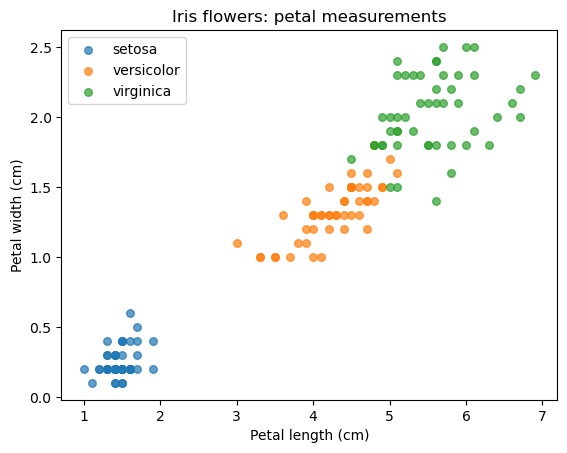

In [3]:
for name, group in df.groupby("species"):
    plt.scatter(group["petal_length_cm"], group["petal_width_cm"], label=name, alpha=0.7, s=30)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris flowers: petal measurements")
plt.legend()
plt.show()

## Prepare the train and test sets

Use `stratify=y` to preserve the three species proportions in both sets. Fix `random_state` for reproducibility.

In [4]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="species")
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)

Training: (105, 4) Testing: (45, 4)


## Fit a KNN pipeline

Scaling is fitted on the training set only; the pipeline applies the same transformation to the test set.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("First five predictions:", predictions[:5].tolist())

First five predictions: ['virginica', 'versicolor', 'versicolor', 'versicolor', 'virginica']


## Evaluate the held-out data

Accuracy is the proportion of correct predictions. A confusion matrix shows *which* species were confused.

Test accuracy: 0.911


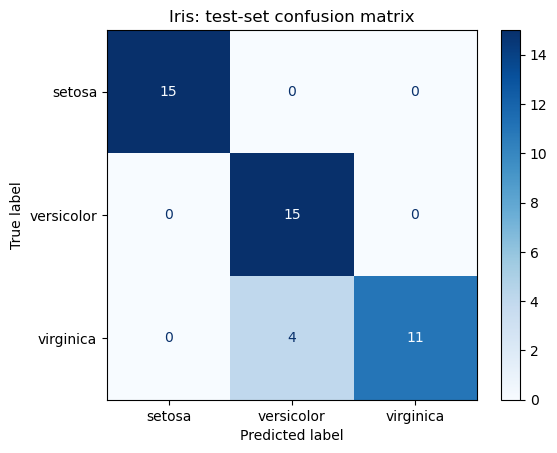

In [6]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
print("Test accuracy:", round(accuracy_score(y_test, predictions), 3))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues")
plt.title("Iris: test-set confusion matrix")
plt.show()

## Your turn — short challenge

Repeat the **same workflow** with `test_size=0.20` and `random_state=42`. Compare the number of test samples and accuracy. Why does one split not prove a model is better?

Try it yourself first. The instructor copy contains a worked answer.

In [7]:
# TODO: write your answer here.
# Hint: reuse the variables created above.